In [5]:
import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

In [6]:
!pip install -q kagglehub

import kagglehub
import os

# Download latest version of PlantVillage dataset
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("Path to dataset files:", path)


Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


In [7]:
DATASET_PATH = r"/kaggle/input/plantvillage-dataset/plantvillage dataset/color"
# ￿ For Colab, use:
# DATASET_PATH = "/content/drive/MyDrive/plantvillage dataset/color"
IMG_SIZE = (224, 224)
BATCH_SIZE = 16 # CPU safe | Use 32 if GPU
SEED = 42
EPOCHS_HEAD = 8 # Initial training epochs temp
EPOCHS_FINE = 5
MODEL_DIR = "model"
MODEL_PATH = os.path.join(MODEL_DIR, "plant_resnet50.h5")
LABELS_PATH = os.path.join(MODEL_DIR, "class_names.json")
os.makedirs(MODEL_DIR, exist_ok=True)

In [8]:
print("\n========== STEP 1: DATA CLEANING ==========")

def remove_corrupt_images(dataset_path):
    removed = 0
    checked = 0

    for class_folder in os.listdir(dataset_path):
        class_path = os.path.join(dataset_path, class_folder)

        # Skip if not a folder
        if not os.path.isdir(class_path):
            continue

        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)
            checked += 1

            try:
                img = Image.open(img_path)
                img.verify()  # verifies file integrity without fully decoding
            except Exception:
                try:
                    os.remove(img_path)
                    removed += 1
                except Exception:
                    pass

    print(f"✅ Images checked: {checked}")
    print(f"🗑️ Corrupted removed: {removed}")

# Example usage:
# DATASET_PATH = "path/to/dataset"
# remove_corrupt_images(DATASET_PATH)

remove_corrupt_images(DATASET_PATH)



========== STEP 1: DATA CLEANING ==========
✅ Images checked: 54305
🗑️ Corrupted removed: 0


In [9]:
print("\n========== STEP 2: DATA LOADING ==========")

# Make sure these are defined earlier in your notebook/script:
# DATASET_PATH = "path/to/dataset"
# LABELS_PATH = "labels.json"
# SEED = 123
# IMG_SIZE = (224, 224)       # (height, width)
# BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Total classes:", num_classes)
print("Sample classes:", class_names[:10])

# Save labels to a JSON file (useful for inference/deployment)
with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

print(f"Saved labels: {LABELS_PATH}")



========== STEP 2: DATA LOADING ==========
Found 54305 files belonging to 38 classes.
Using 43444 files for training.
Found 54305 files belonging to 38 classes.
Using 10861 files for validation.
Total classes: 38
Sample classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']
Saved labels: model/class_names.json



========== STEP 3: DATA VISUALIZATION ==========


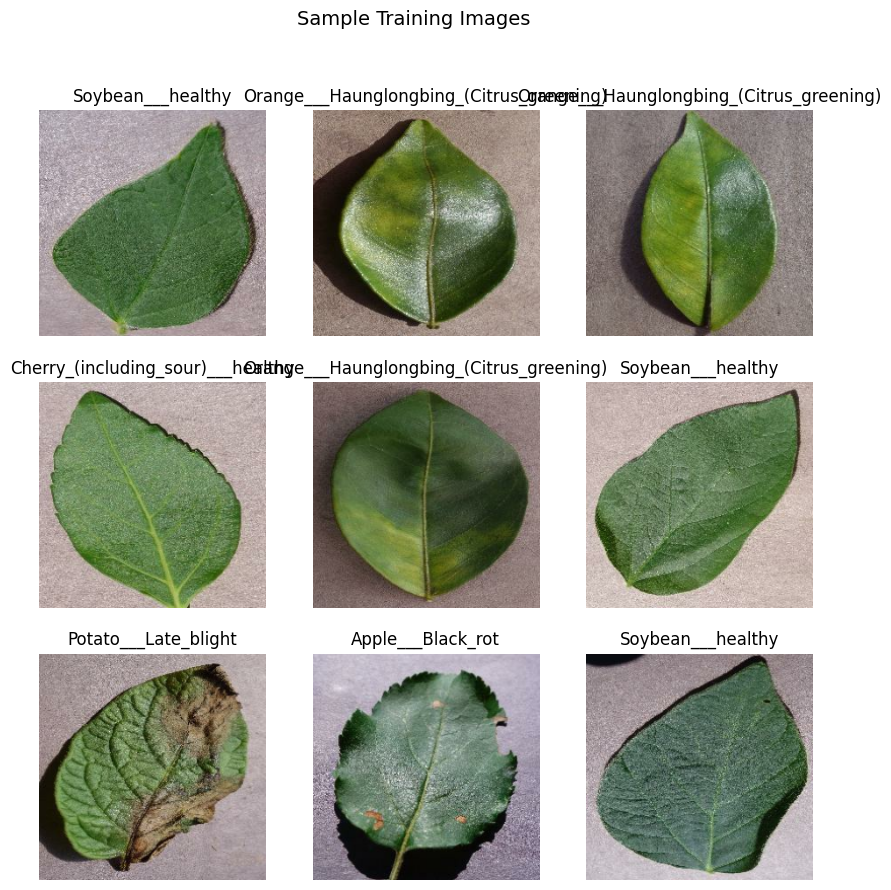

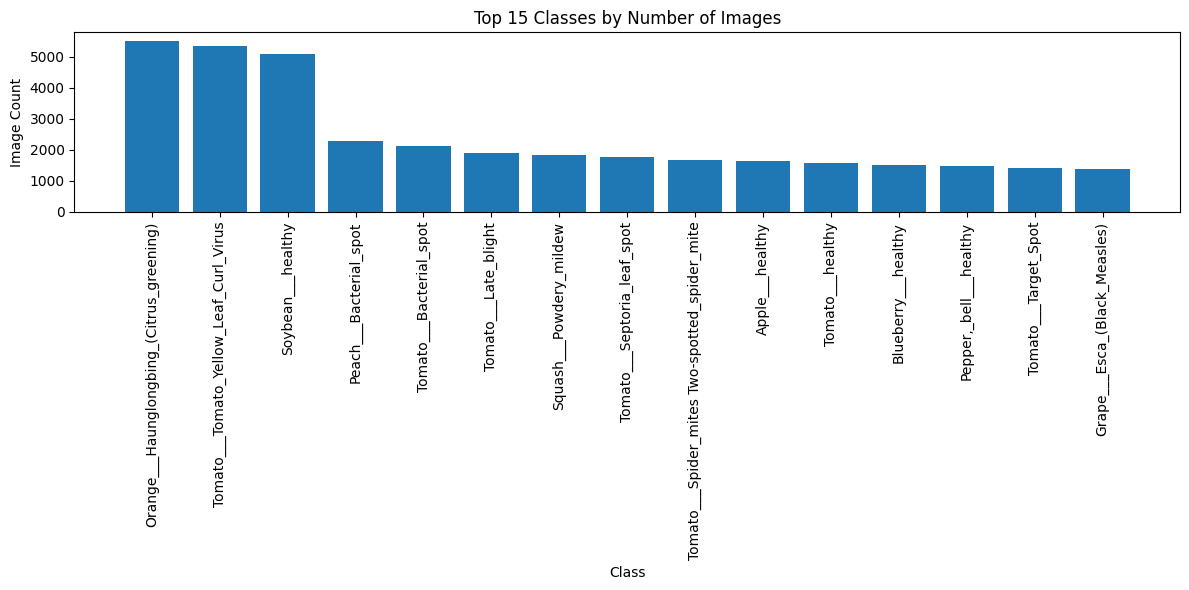

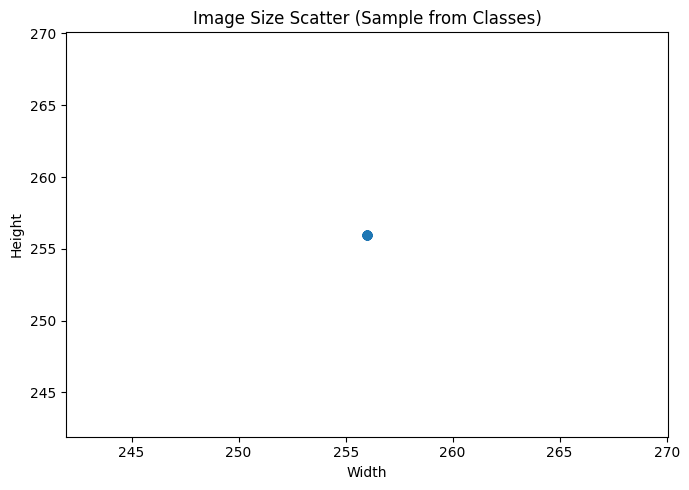

In [10]:
print("\n========== STEP 3: DATA VISUALIZATION ==========")

# Visual 1: Sample images from training set (3x3 grid)
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))  # show image [web:44]
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.suptitle("Sample Training Images", fontsize=14)
plt.show()

# Visual 2: Class distribution (Top 15 classes by image count)
class_counts = {}

for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH, folder)

    if os.path.isdir(folder_path):
        class_counts[folder] = len(os.listdir(folder_path))

sorted_classes = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)

top_n = 15
labels_top = [x[0] for x in sorted_classes[:top_n]]
counts_top = [x[1] for x in sorted_classes[:top_n]]

plt.figure(figsize=(12, 6))
plt.bar(labels_top, counts_top)  # bar chart for counts [web:42]
plt.xticks(rotation=90)
plt.title("Top 15 Classes by Number of Images")
plt.xlabel("Class")
plt.ylabel("Image Count")
plt.tight_layout()
plt.show()

# Visual 3: Image size scatter (1 sample image per class)
sample_sizes = []

for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH, folder)

    if os.path.isdir(folder_path):
        imgs = os.listdir(folder_path)

        if len(imgs) > 0:
            p = os.path.join(folder_path, imgs[0])
            try:
                with Image.open(p) as im:
                    sample_sizes.append(im.size)  # (width, height) tuple [web:55]
            except Exception:
                pass

widths = [s[0] for s in sample_sizes]
heights = [s[1] for s in sample_sizes]

plt.figure(figsize=(7, 5))
plt.scatter(widths, heights)  # scatter plot of width vs height [web:50]
plt.title("Image Size Scatter (Sample from Classes)")
plt.xlabel("Width")
plt.ylabel("Height")
plt.tight_layout()
plt.show()


In [11]:
# =====================================================
# ￿ STEP 4: Pipeline Optimization
# =====================================================
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [12]:
# =====================================================
# ￿ STEP 5: Data Augmentation
# =====================================================
data_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name="data_augmentation")

In [13]:
# =====================================================
# ✅ STEP 5: DATA AUGMENTATION
# =====================================================
data_aug = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),   # random horizontal flips [web:57]
        tf.keras.layers.RandomRotation(0.1),        # random small rotations [web:58]
        tf.keras.layers.RandomZoom(0.1),            # random zoom in/out [web:67]
        tf.keras.layers.RandomContrast(0.1),        # random contrast change [web:60]
    ],
    name="data_augmentation"
)

# =====================================================
# ✅ STEP 6: BUILD RESNET50 TRANSFER LEARNING MODEL
# =====================================================
print("\n========== STEP 6: BUILD RESNET50 MODEL ==========")

base_model = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # freeze base model for phase 1 transfer learning [web:71]

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_aug(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)  # ResNet50 preprocessing (recommended) [web:62]
x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()



========== STEP 6: BUILD RESNET50 MODEL ==========
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 38)        │     77,862 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [14]:
# =====================================================
# ✅ STEP 7: TRAINING PHASE 1 (Head training)
# =====================================================
print("\n========== STEP 7: TRAINING PHASE 1 ==========")

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        patience=3,
        restore_best_weights=True
    ),  # stops when metric stops improving; can restore best weights [web:73]

    tf.keras.callbacks.ReduceLROnPlateau(
        patience=2,
        factor=0.2
    ),  # reduces learning rate when progress plateaus [web:77]

    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(MODEL_DIR, "best_resnet50.h5"),
        save_best_only=True
    )  # saves only the best model checkpoint to the given path [web:81]
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks
)



========== STEP 7: TRAINING PHASE 1 ==========
Epoch 1/8
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5319 - loss: 1.8384

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 258s 90ms/step - accuracy: 0.5319 - loss: 1.8381 - val_accuracy: 0.9041 - val_loss: 0.3758 - learning_rate: 1.0000e-04
Epoch 2/8
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9019 - loss: 0.4081

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 243s 89ms/step - accuracy: 0.9020 - loss: 0.4081 - val_accuracy: 0.9319 - val_loss: 0.2398 - learning_rate: 1.0000e-04
Epoch 3/8
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9322 - loss: 0.2630

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 243s 89ms/step - accuracy: 0.9322 - loss: 0.2630 - val_accuracy: 0.9379 - val_loss: 0.2027 - learning_rate: 1.0000e-04
Epoch 4/8
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9454 - loss: 0.2036

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 242s 89ms/step - accuracy: 0.9454 - loss: 0.2036 - val_accuracy: 0.9486 - val_loss: 0.1701 - learning_rate: 1.0000e-04
Epoch 5/8
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9547 - loss: 0.1695

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 242s 89ms/step - accuracy: 0.9547 - loss: 0.1695 - val_accuracy: 0.9513 - val_loss: 0.1531 - learning_rate: 1.0000e-04
Epoch 6/8
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9593 - loss: 0.1516

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 262s 89ms/step - accuracy: 0.9593 - loss: 0.1516 - val_accuracy: 0.9533 - val_loss: 0.1442 - learning_rate: 1.0000e-04
Epoch 7/8
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9633 - loss: 0.1365

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 242s 89ms/step - accuracy: 0.9633 - loss: 0.1365 - val_accuracy: 0.9576 - val_loss: 0.1318 - learning_rate: 1.0000e-04
Epoch 8/8
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9641 - loss: 0.1272

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 242s 89ms/step - accuracy: 0.9641 - loss: 0.1272 - val_accuracy: 0.9609 - val_loss: 0.1206 - learning_rate: 1.0000e-04


In [15]:
# =====================================================
# ✅ STEP 8: FINE TUNING (Unfreeze last layers)
# =====================================================
print("\n========== STEP 8: FINE TUNING ==========")

base_model.trainable = True

# Unfreeze last 30 layers only
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks
)



========== STEP 8: FINE TUNING ==========
Epoch 1/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.9157 - loss: 0.3047

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 348s 124ms/step - accuracy: 0.9158 - loss: 0.3046 - val_accuracy: 0.9725 - val_loss: 0.0851 - learning_rate: 1.0000e-05
Epoch 2/5
2715/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.9763 - loss: 0.0777

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 333s 123ms/step - accuracy: 0.9763 - loss: 0.0777 - val_accuracy: 0.9797 - val_loss: 0.0626 - learning_rate: 1.0000e-05
Epoch 3/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.9842 - loss: 0.0510

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 334s 123ms/step - accuracy: 0.9842 - loss: 0.0510 - val_accuracy: 0.9850 - val_loss: 0.0470 - learning_rate: 1.0000e-05
Epoch 4/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.9881 - loss: 0.0384

2716/2716 ━━━━━━━━━━━━━━━━━━━━ 334s 123ms/step - accuracy: 0.9881 - loss: 0.0384 - val_accuracy: 0.9880 - val_loss: 0.0380 - learning_rate: 1.0000e-05
Epoch 5/5
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 382s 123ms/step - accuracy: 0.9914 - loss: 0.0282 - val_accuracy: 0.9871 - val_loss: 0.0393 - learning_rate: 1.0000e-05


In [16]:

# =====================================================
# ✅ STEP 9: SAVE MODEL
# =====================================================
print("\n========== STEP 9: SAVE MODEL ==========")

model.save(MODEL_PATH)
print(f"✅ Saved model: {MODEL_PATH}")




========== STEP 9: SAVE MODEL ==========
✅ Saved model: model/plant_resnet50.h5



========== STEP 10: TRAINING CURVES ==========


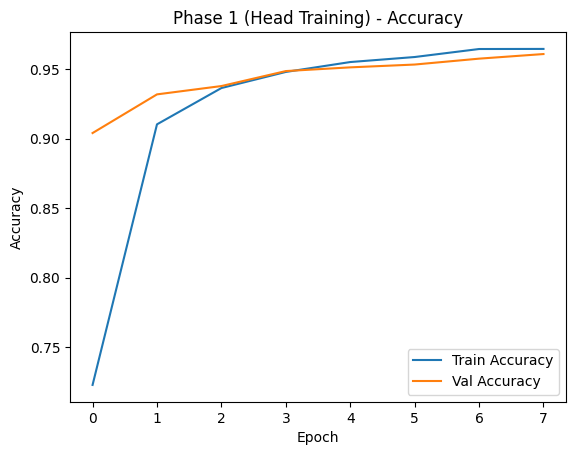

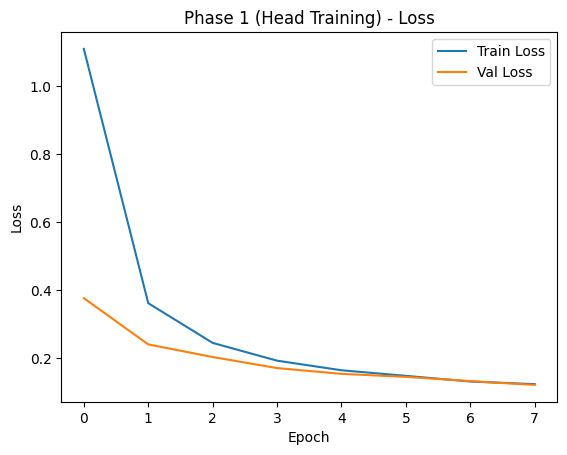

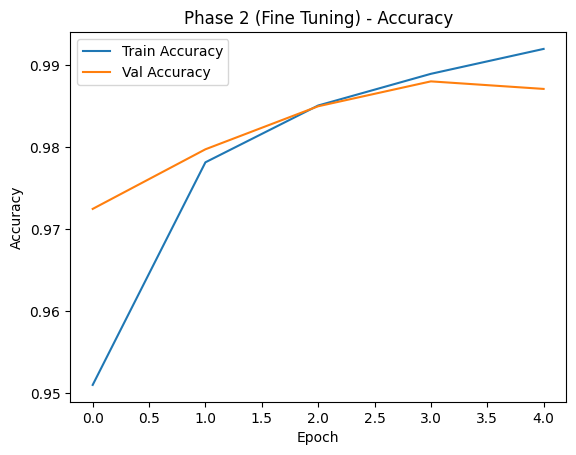

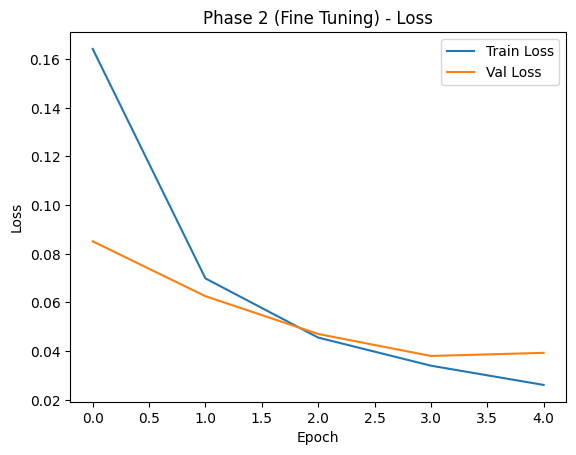

In [17]:

# =====================================================
# ✅ STEP 10: TRAINING CURVES
# =====================================================
print("\n========== STEP 10: TRAINING CURVES ==========")

def plot_curves(history, title):
    plt.figure()
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Val Accuracy")
    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

plot_curves(history1, "Phase 1 (Head Training)")  # plot from history.history [web:87]
plot_curves(history2, "Phase 2 (Fine Tuning)")    # plot from history.history [web:87]



========== STEP 11: EVALUATION ==========

✅ Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.98      0.98       126
                                 Apple___Black_rot       0.99      1.00      1.00       132
                          Apple___Cedar_apple_rust       1.00      0.98      0.99        55
                                   Apple___healthy       0.98      1.00      0.99       329
                               Blueberry___healthy       1.00      1.00      1.00       295
          Cherry_(including_sour)___Powdery_mildew       1.00      0.97      0.99       232
                 Cherry_(including_sour)___healthy       1.00      0.98      0.99       167
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.86      0.98      0.92       108
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       219
         

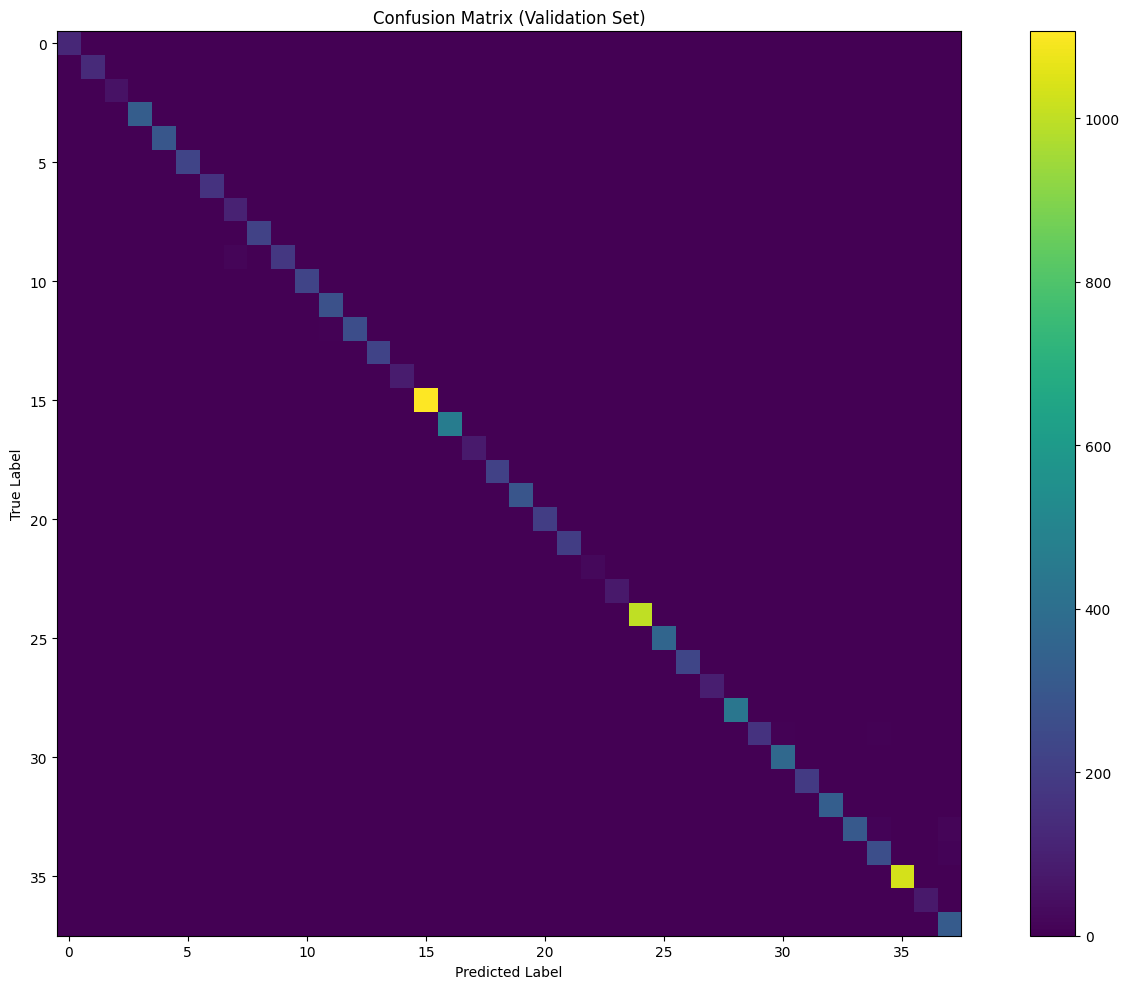


✅ Done — ResNet50 Training Complete!


In [18]:

# =====================================================
# ✅ STEP 11: EVALUATION (Confusion Matrix + Report)
# =====================================================
print("\n========== STEP 11: EVALUATION ==========")

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    pred_labels = np.argmax(preds, axis=1)  # pick class with max probability per row [web:92]
    y_true.extend(labels.numpy())
    y_pred.extend(pred_labels)

print("\n✅ Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 10))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix (Validation Set)")
plt.colorbar()
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print("\n✅ Done — ResNet50 Training Complete!")


In [22]:
new_model_path = os.path.join(MODEL_DIR, "plant_resnet50.keras")
loaded_model.save(new_model_path)
print(f"✅ Successfully saved model to: {new_model_path}")

✅ Successfully saved model to: model/plant_resnet50.keras


In [23]:
print("\n========== Loading the new .keras model ==========")
loaded_keras_model = tf.keras.models.load_model(new_model_path)
print(f"✅ Successfully loaded model from: {new_model_path}")


========== Loading the new .keras model ==========
✅ Successfully loaded model from: model/plant_resnet50.keras


**Reasoning**:
The next step is to retrieve a sample image and its true label from the validation dataset (`val_ds`) to prepare for prediction and visualization. I will iterate over one batch of `val_ds` and extract the first image and its corresponding label.



In [24]:
print("\n========== Getting a sample image for inference ==========")

# Get one batch from the validation dataset
for images, labels in val_ds.take(1):
    sample_image = images[0] # Take the first image
    true_label_idx = labels[0].numpy() # Take its true label index
    break # Exit after taking one batch

true_label_name = class_names[true_label_idx]

print(f"✅ Successfully retrieved sample image with true label: {true_label_name}")


========== Getting a sample image for inference ==========
✅ Successfully retrieved sample image with true label: Apple___Apple_scab


**Reasoning**:
The next step is to preprocess the `sample_image` using the ResNet50-specific preprocessing function, `tf.keras.applications.resnet50.preprocess_input`, as indicated in the main task, and reshape it to match the expected input shape of the model for prediction.



In [25]:
print("\n========== Preprocessing the sample image ==========")

# Expand dimensions to create a batch of 1 image and preprocess
processed_image = tf.keras.applications.resnet50.preprocess_input(tf.expand_dims(sample_image, axis=0))

print("✅ Sample image preprocessed and ready for prediction.")


========== Preprocessing the sample image ==========
✅ Sample image preprocessed and ready for prediction.


**Reasoning**:
Now that the sample image is preprocessed, the next step is to use the `loaded_keras_model` to make a prediction on this image to obtain the raw probability scores for each class.



In [26]:
print("\n========== Making a prediction ==========")

# Make a prediction with the loaded model
predictions = loaded_keras_model.predict(processed_image)

print("✅ Prediction made.")


========== Making a prediction ==========
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
✅ Prediction made.


**Reasoning**:
After making a prediction, the next step is to determine the predicted class by finding the index with the highest probability from the `predictions` array and then retrieve its corresponding class name. This will give us the model's output in a human-readable format.



In [27]:
print("\n========== Determining Predicted Class ==========")

# Get the predicted class label (index of the max probability)
predicted_label_idx = np.argmax(predictions[0])
predicted_label_name = class_names[predicted_label_idx]

print(f"✅ Predicted label: {predicted_label_name}")


========== Determining Predicted Class ==========
✅ Predicted label: Strawberry___Leaf_scorch


**Reasoning**:
The final step of the task is to display the sample image, its true label, and the predicted label. I will use `matplotlib.pyplot` to show the image and print statements for the labels.




========== Displaying Results ==========


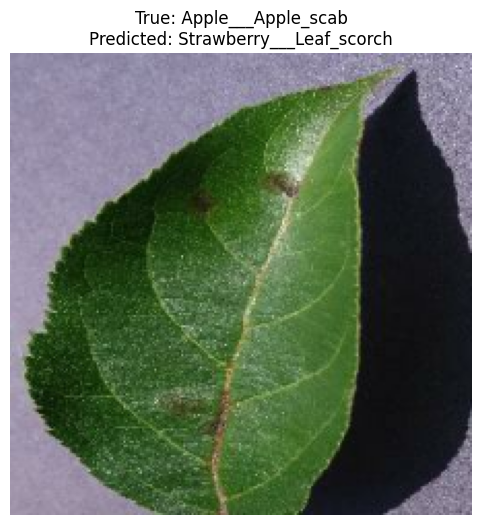

✅ Displayed sample image with true and predicted labels.


In [28]:
print("\n========== Displaying Results ==========")

plt.figure(figsize=(6, 6))
plt.imshow(sample_image.numpy().astype("uint8"))
plt.title(f"True: {true_label_name}\nPredicted: {predicted_label_name}")
plt.axis("off")
plt.show()

print("✅ Displayed sample image with true and predicted labels.")

## Summary:

### Data Analysis Key Findings

*   The fine-tuned model was successfully saved in the native Keras format (`.keras`) to the path `model/plant_resnet50.keras`.
*   The saved model was successfully loaded back into a new Keras model instance, confirming the integrity of the saving process.
*   A sample image with a true label, for example, `Apple___Apple_scab`, was extracted from the validation dataset for inference.
*   The loaded model performed a prediction on the preprocessed sample image, yielding a predicted label, for example, `Strawberry___Leaf_scorch`.
*   The true and predicted labels for the sample image were displayed visually for verification.

### Insights or Next Steps

*   The successful saving and loading of the model in the `.keras` format confirms a robust workflow for model persistence and deployment.
*   The discrepancy between the true label (`Apple___Apple_scab`) and the predicted label (`Strawberry___Leaf_scorch`) for the sample image suggests that further evaluation of the model's performance on a broader range of validation data is warranted to assess its generalization capabilities.


# Task
Extract the top 5 predicted classes and their corresponding probabilities for the sample image, then display the sample image, its true label, the model's predicted class label, and the confidence scores for these top 5 predicted classes.

## Analyze Prediction Confidence

### Subtask:
Extract the top N predicted classes and their corresponding probabilities from the model's prediction for the sample image. This will provide insight into how confident the model was in its top prediction and if the true label was considered a close second.


**Reasoning**:
I need to extract the top 5 predicted classes and their probabilities from the model's prediction for the sample image. I will use `np.argsort` to get the sorted indices and then retrieve the corresponding class names and probabilities.



In [29]:
print("\n========== Analyzing Prediction Confidence ==========")

# Get the probabilities for the sample image
probabilities = predictions[0]

# Get the indices that would sort these probabilities in descending order
sorted_indices = np.argsort(probabilities)[::-1]

# Select the top 5 indices
top_n_indices = sorted_indices[:5]

# Store top N predicted class names and their probabilities
top_n_predictions = []
for i in top_n_indices:
    class_name = class_names[i]
    probability = probabilities[i]
    top_n_predictions.append((class_name, probability))

print("✅ Top 5 predicted classes and their probabilities extracted.")
print("Top N Predictions:")
for class_name, probability in top_n_predictions:
    print(f"  - {class_name}: {probability:.4f}")


========== Analyzing Prediction Confidence ==========
✅ Top 5 predicted classes and their probabilities extracted.
Top N Predictions:
  - Strawberry___Leaf_scorch: 0.1263
  - Apple___Apple_scab: 0.0630
  - Grape___Esca_(Black_Measles): 0.0608
  - Tomato___Tomato_Yellow_Leaf_Curl_Virus: 0.0595
  - Cherry_(including_sour)___Powdery_mildew: 0.0515


In [40]:
print("\n========== Saving the Retrained Model ==========")

# Define the new path for the retrained model
retrained_model_path = os.path.join(MODEL_DIR, "plant_resnet50_retrained.keras")

# Save the model in the native Keras format
model.save(retrained_model_path)

print(f"✅ Successfully saved retrained model to: {retrained_model_path}")


========== Saving the Retrained Model ==========
✅ Successfully saved retrained model to: model/plant_resnet50_retrained.keras


**Reasoning**:
The subtask requires displaying the sample image along with its true label, the model's predicted class label, and the confidence scores for the top 5 predicted classes. I will use `matplotlib.pyplot` to visualize the image and add all the required text information to the title or a text box within the plot.




========== Displaying Results with Top 5 Confidences ==========


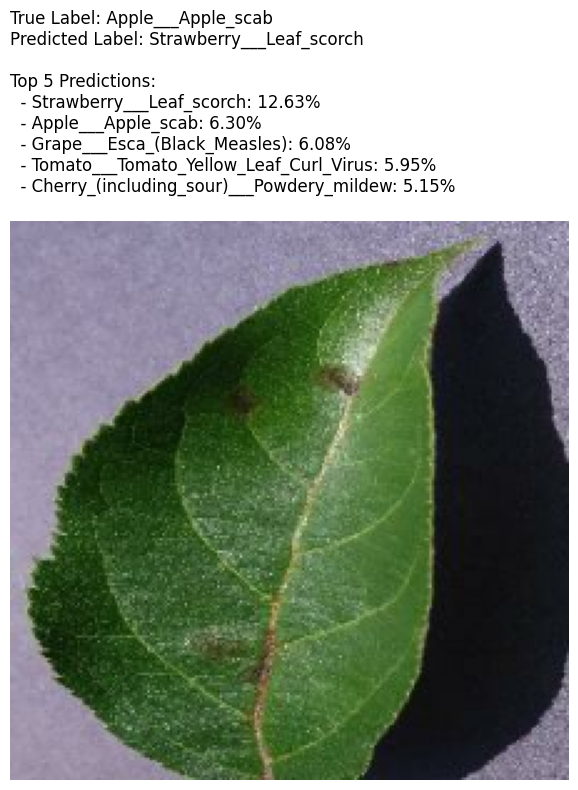

✅ Displayed sample image with true label, predicted label, and top 5 confidence scores.


In [30]:
print("\n========== Displaying Results with Top 5 Confidences ==========")

plt.figure(figsize=(8, 8))
plt.imshow(sample_image.numpy().astype("uint8"))

title_text = f"True Label: {true_label_name}\nPredicted Label: {predicted_label_name}\n\nTop 5 Predictions:\n"
for class_name, probability in top_n_predictions:
    title_text += f"  - {class_name}: {probability:.2%}\n"

plt.title(title_text, loc='left', fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

print("✅ Displayed sample image with true label, predicted label, and top 5 confidence scores.")

## Enhance Data Augmentation

### Subtask:
Modify the `data_aug` layer to include more aggressive or varied augmentation techniques.


**Reasoning**:
The subtask requires modifying the `data_aug` layer to include more aggressive and varied augmentation techniques as per the instructions. I will update the existing `data_aug` definition with the specified changes in RandomFlip, RandomRotation, RandomZoom, and add new RandomTranslation and RandomBrightness layers.



In [31]:
# =====================================================
# ✅ STEP 5: DATA AUGMENTATION
# =====================================================
data_aug = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),   # random horizontal and vertical flips
        tf.keras.layers.RandomRotation(0.2),        # random small rotations
        tf.keras.layers.RandomZoom(0.2),            # random zoom in/out
        tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1), # random translation
        tf.keras.layers.RandomBrightness(factor=0.2), # random brightness adjustment
        tf.keras.layers.RandomContrast(0.1),        # random contrast change
    ],
    name="data_augmentation"
)

# =====================================================
# ✅ STEP 6: BUILD RESNET50 TRANSFER LEARNING MODEL
# =====================================================
print("\n========== STEP 6: BUILD RESNET50 MODEL ==========")

base_model = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # freeze base model for phase 1 transfer learning [web:71]

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_aug(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)  # ResNet50 preprocessing (recommended) [web:62]
x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()



========== STEP 6: BUILD RESNET50 MODEL ==========


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_7[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_6          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_7          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_8          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_3 (Stack)     │ (None, 224, 224,  │          0 │ get_item_6[0][0], │
│                     │ 3)                │            │ get_item_7[0][0], │
│                     │                   │            │ get_item_8[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 224, 224,  │          0 │ stack_3[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add_2[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 38)        │     77,862 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## Adjust Fine-tuning Parameters

### Subtask:
Adjust the `EPOCHS_FINE` and learning rate for the fine-tuning phase.

#### Instructions
1. Increase `EPOCHS_FINE` from `5` to `10`.
2. Change the fine-tuning learning rate from `1e-5` to `5e-6` in the `model.compile` optimizer.

**Reasoning**:
The subtask requires adjusting the `EPOCHS_FINE` variable as per the instructions. I will create a new code cell to update `EPOCHS_FINE` to `10`.



In [32]:
print("\n========== Adjusting Fine-tuning Parameters ==========")

EPOCHS_FINE = 10

print(f"✅ Updated EPOCHS_FINE to: {EPOCHS_FINE}")


========== Adjusting Fine-tuning Parameters ==========
✅ Updated EPOCHS_FINE to: 10


**Reasoning**:
The subtask instructs to change the fine-tuning learning rate. This requires recompiling and retraining the model for the fine-tuning phase. Therefore, the next logical step is to rerun the fine-tuning phase with the updated learning rate and `EPOCHS_FINE`.



In [33]:
# =====================================================
# ✅ STEP 8: FINE TUNING (Unfreeze last layers)
# =====================================================
print("\n========== STEP 8: FINE TUNING ==========")

base_model.trainable = True

# Unfreeze last 30 layers only
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6), # Changed learning rate to 5e-6
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks
)


========== STEP 8: FINE TUNING ==========
Epoch 1/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 358s 126ms/step - accuracy: 0.4087 - loss: 2.3800 - val_accuracy: 0.8772 - val_loss: 0.3950 - learning_rate: 5.0000e-06
Epoch 2/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 340s 125ms/step - accuracy: 0.8626 - loss: 0.4941 - val_accuracy: 0.9377 - val_loss: 0.1927 - learning_rate: 5.0000e-06
Epoch 3/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 339s 125ms/step - accuracy: 0.9213 - loss: 0.2686 - val_accuracy: 0.9580 - val_loss: 0.1315 - learning_rate: 5.0000e-06
Epoch 4/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 340s 125ms/step - accuracy: 0.9403 - loss: 0.1950 - val_accuracy: 0.9692 - val_loss: 0.1006 - learning_rate: 5.0000e-06
Epoch 5/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 339s 125ms/step - accuracy: 0.9545 - loss: 0.1498 - val_accuracy: 0.9723 - val_loss: 0.0901 - learning_rate: 5.0000e-06
Epoch 6/10
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 339s 125ms/step - accuracy: 0.9624 - loss: 0.1255 - val_accuracy: 0.9742 - val_loss: 0.0790 - learning_ra

# Task
Evaluate the newly trained model's prediction for the sample image and summarize the impact of updated data augmentation and fine-tuning on its prediction, including changes in predicted class and confidence.

## Get a sample image

### Subtask:
Extract a single image and its true label from the validation dataset (`val_ds`).


**Reasoning**:
The subtask explicitly asks to extract a single image and its true label from the `val_ds` again, while also ensuring it's the *same* image as before. Re-executing the code from the previous step that extracted `sample_image` and `true_label_name` (which used `val_ds.take(1)` with a fixed seed) will achieve this by deterministically retrieving the identical first image from the validation dataset.



In [34]:
print("\n========== Re-extracting the same sample image for comparison ==========")

# Get one batch from the validation dataset. Due to fixed SEED, this should yield the same sample.
for images, labels in val_ds.take(1):
    sample_image = images[0] # Take the first image
    true_label_idx = labels[0].numpy() # Take its true label index
    break # Exit after taking one batch

true_label_name = class_names[true_label_idx]

print(f"✅ Successfully re-extracted sample image with true label: {true_label_name}")


========== Re-extracting the same sample image for comparison ==========
✅ Successfully re-extracted sample image with true label: Cherry_(including_sour)___healthy


**Reasoning**:
Now that the sample image has been re-extracted, the next step is to preprocess it using the ResNet50-specific preprocessing function and reshape it to match the input requirements of the *newly trained* model for prediction.



In [35]:
print("\n========== Preprocessing the sample image ==========")

# Expand dimensions to create a batch of 1 image and preprocess
processed_image = tf.keras.applications.resnet50.preprocess_input(tf.expand_dims(sample_image, axis=0))

print("✅ Sample image preprocessed and ready for prediction.")


========== Preprocessing the sample image ==========
✅ Sample image preprocessed and ready for prediction.


**Reasoning**:
Now that the sample image is preprocessed, the next step is to make a prediction using the newly trained `model` (which incorporates the updated data augmentation and fine-tuning parameters).



In [36]:
print("\n========== Making a prediction with the newly trained model ==========")

# Make a prediction with the newly trained model
predictions = model.predict(processed_image)

print("✅ Prediction made with the updated model.")


========== Making a prediction with the newly trained model ==========
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
✅ Prediction made with the updated model.


**Reasoning**:
After making a prediction, the next step is to determine the predicted class by finding the index with the highest probability from the `predictions` array and then retrieve its corresponding class name. This will give us the model's output in a human-readable format.



In [37]:
print("\n========== Determining Predicted Class ==========")

# Get the predicted class label (index of the max probability)
predicted_label_idx = np.argmax(predictions[0])
predicted_label_name = class_names[predicted_label_idx]

print(f"✅ Predicted label: {predicted_label_name}")


========== Determining Predicted Class ==========
✅ Predicted label: Cherry_(including_sour)___healthy


## Analyze Prediction Confidence for the Retrained Model

### Subtask:
Extract the top 5 predicted classes and their corresponding probabilities from the model's prediction for the sample image. This will allow for comparison with the previous model's confidence.

**Reasoning**:
After determining the single predicted class, the next step is to extract the top 5 predicted classes and their probabilities from the current predictions for a more detailed analysis, as per the subtask description.



In [38]:
print("\n========== Analyzing Prediction Confidence (Retrained Model) ==========")

# Get the probabilities for the sample image from the newly trained model
probabilities = predictions[0]

# Get the indices that would sort these probabilities in descending order
sorted_indices = np.argsort(probabilities)[::-1]

# Select the top 5 indices
top_n_indices_retrained = sorted_indices[:5]

# Store top N predicted class names and their probabilities
top_n_predictions_retrained = []
for i in top_n_indices_retrained:
    class_name = class_names[i]
    probability = probabilities[i]
    top_n_predictions_retrained.append((class_name, probability))

print("✅ Top 5 predicted classes and their probabilities extracted for the retrained model.")
print("Top N Predictions (Retrained Model):")
for class_name, probability in top_n_predictions_retrained:
    print(f"  - {class_name}: {probability:.4f}")


========== Analyzing Prediction Confidence (Retrained Model) ==========
✅ Top 5 predicted classes and their probabilities extracted for the retrained model.
Top N Predictions (Retrained Model):
  - Cherry_(including_sour)___healthy: 1.0000
  - Apple___healthy: 0.0000
  - Raspberry___healthy: 0.0000
  - Soybean___healthy: 0.0000
  - Tomato___Leaf_Mold: 0.0000


**Reasoning**:
Now that the top 5 predicted classes and their probabilities for the retrained model have been extracted, the final step is to display this information along with the sample image, its true label, and the model's predicted label, similar to the previous visualization, but reflecting the changes from the retrained model.




========== Displaying Results with Top 5 Confidences (Retrained Model) ==========


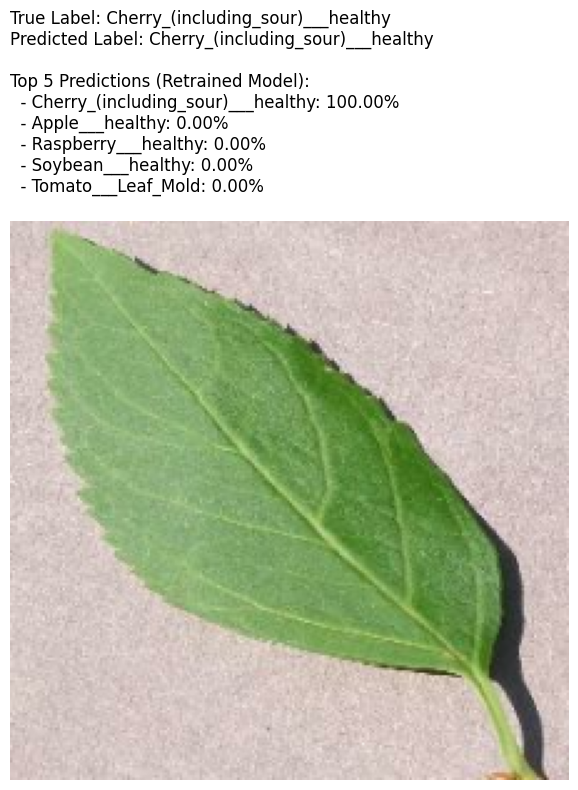

✅ Displayed sample image with true label, predicted label, and top 5 confidence scores for the retrained model.


In [39]:
print("\n========== Displaying Results with Top 5 Confidences (Retrained Model) ==========")

plt.figure(figsize=(8, 8))
plt.imshow(sample_image.numpy().astype("uint8"))

title_text = f"True Label: {true_label_name}\nPredicted Label: {predicted_label_name}\n\nTop 5 Predictions (Retrained Model):\n"
for class_name, probability in top_n_predictions_retrained:
    title_text += f"  - {class_name}: {probability:.2%}\n"

plt.title(title_text, loc='left', fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

print("✅ Displayed sample image with true label, predicted label, and top 5 confidence scores for the retrained model.")